# ComCon Vignette 1.1: Single-Species Workflow Using Interactive Mode

**A complete single-species workflow using Interactive Mode**

---

## What This Vignette Covers

This vignette takes you through a complete connectivity analysis for a single species using ComCon's Interactive Mode. By the end, you will have:

- Run the full 6-step workflow from hydrodynamic data setup through to connectivity analysis
- Calculated basic connectivity metrics (Type 1 analysis) including settlement success, mortality, dispersal distances and local recruitment
- Interpreted the results to understand what they tell you about your species' dispersal

We focus on a single species here, *Patella vulgata* (the common limpet), to keep things simple while you get comfortable with the workflow. Vignettes 2 and 3 build on this foundation with multi-species workflows and more advanced analyses hypothesis testing.

### Why Interactive Mode?
ComCon offers three modes for running analyses. Interactive Mode guides you step-by-step through the full workflow with prompts, explanations and progress tracking at each stage. This is the recommended starting point because it:

- Does not require any prior coding experience
- Walks you through each decision with context so you understand what each parameter does
- Displays progress indicators so you always know where you are in the workflow
- Includes built-in explanations and tips throughout

Vignettes 1.2 and 1.3 demonstrate Manual and Automatic Mode respectively, which offer more flexibility for experienced users. The underlying functions and parameters are identical across all three modes.

### What You Will Need

- ComCon installed in a Conda environment (see the User Guide, Part 1)
- A free Copernicus Marine Service account ([register here](https://data.marine.copernicus.eu/register))
- Approximately 2 hours (including simulation time)

### Why *Patella vulgata*?

*P. vulgata* is an ideal starting species for several reasons. It is one of the most common rocky shore species in the NE Atlantic, making it well-studied with easily accessible trait data. Its short pelagic larval duration (PLD; 2–10 days) means the simulation will run quickly.

*P. vulgata* is a keystone grazer on NE Atlantic intertidal rocky shores, found from northern Norway to the Mediterranean. It is found on any hard substratum including rocks, stones and in rock pools, with higher abundances in wave exposed conditions. 

Spawning is annual, occurring October to January in southern England (though timing varies with latitude), with eggs and sperm broadcast into the water column. Spawning has been found to be triggered by heavy wave action and onshore winds. The planktotrophic trochophore larvae spend 2–10 days in the plankton before settling onto rocky substrate. Individuals typically have a life span of 11 to 20 years. 

This species is considered a keystone species in NE Atlantic rocky shores, having been found to significantly structure their surrounding ecological communities through their grazing behaviour, specifically fucoid and barnacle cover. Therefore, understanding *P. vulgata's* dispersal throughout its range and which populations are connected is important for predicting how entire rocky shore communities may shift under current and future stressors as well as to identify sites whose protection would benefit the wider network.

For further biological information see the full MarLIN species profile: https://www.marlin.ac.uk/species/detail/1371

<table style="text-align: left; margin-left: 0;">
  <thead>
    <tr>
      <th>Trait</th>
      <th>Value</th>
      <th>Source</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Spawning season</td>
      <td>October – January</td>
      <td>MarLin (Hill, 2008)</td>
    </tr>
    <tr>
      <td>Minimum PLD</td>
      <td>2 days</td>
      <td>MarLin (Hill, 2008)</td>
    </tr>
    <tr>
      <td>Maximum PLD</td>
      <td>10 days</td>
      <td>MarLin (Hill, 2008)</td>
    </tr>
    <tr>
      <td>Habitat</td>
      <td>Rocky intertidal (coastal)</td>
      <td>—</td>
    </tr>
  </tbody>
</table>


### Research Questions
Each ComCon vignette addresses a different type of ecological question using the same underlying simulation framework:

**Vignette 1** (this vignette):

→ **Type 1: Connectivity Metrics**
- What are the general dispersal characteristics of *P. vulgata* along the southern English coast? For example:
    - How many larvae successfully settle?
    - How far do they travel?
    - Are populations self-sustaining through local recruitment or do they depend on larval supply from elsewhere?

**Vignette 2:** 

→ **Type 2: Network Analysis**
- Which sites are most important for maintaining connectivity across the community?
- Where are the connectivity hotspots, stepping stones and key source populations?
- Where are critical sink populations dependent on external larval supply?

**Vignette 3:** 

→ **Type 3: Trait Sensitivity Analysis**
- Which connectivity hotspots are robust to trait uncertainty and which are fragile?
- Do species-specific dispersal traits significantly shape connectivity patterns or are patterns primarily driven by oceanographic currents and coastal geography?
- What happens to the connectivity network if spawning windows shift (e.g. under climate change)?

### Before You Begin

A few things to note as you work through this vignette:

- File paths and folder locations will depend on your own computer setup. Wherever the vignette shows a file path, yours will be different. Just make sure you know where your working directory is.
- Saving prompts: ComCon will occasionally ask whether you want to save outputs (e.g., "Do you want to export the data to a NetCDF file?") or review parameters. These prompts are not described in detail below as the choices depend on your preferences. When in doubt, the defaults (shown in square brackets) are a safe choice.
- Parameter files: ComCon automatically saves your settings to JSON files (e.g., hydrodynamic_parameters.json) so you can reload them later without re-entering everything. This is useful if you need to restart your analysis.


### Getting Started

Open a new notebook in Jupyter Lab and make sure your `comcon` environment is active (you should see `(comcon)` in your terminal). If you need help with this, see the User Guide, Part 1.

Import ComCon by running the cell below. You will see the ComCon welcome message and the option to select your mode.

When the mode selection appears, choose Interactive Mode and click Start.

You will see a message explaining that Interactive Mode guides you step-by-step through the 6-step workflow.

---


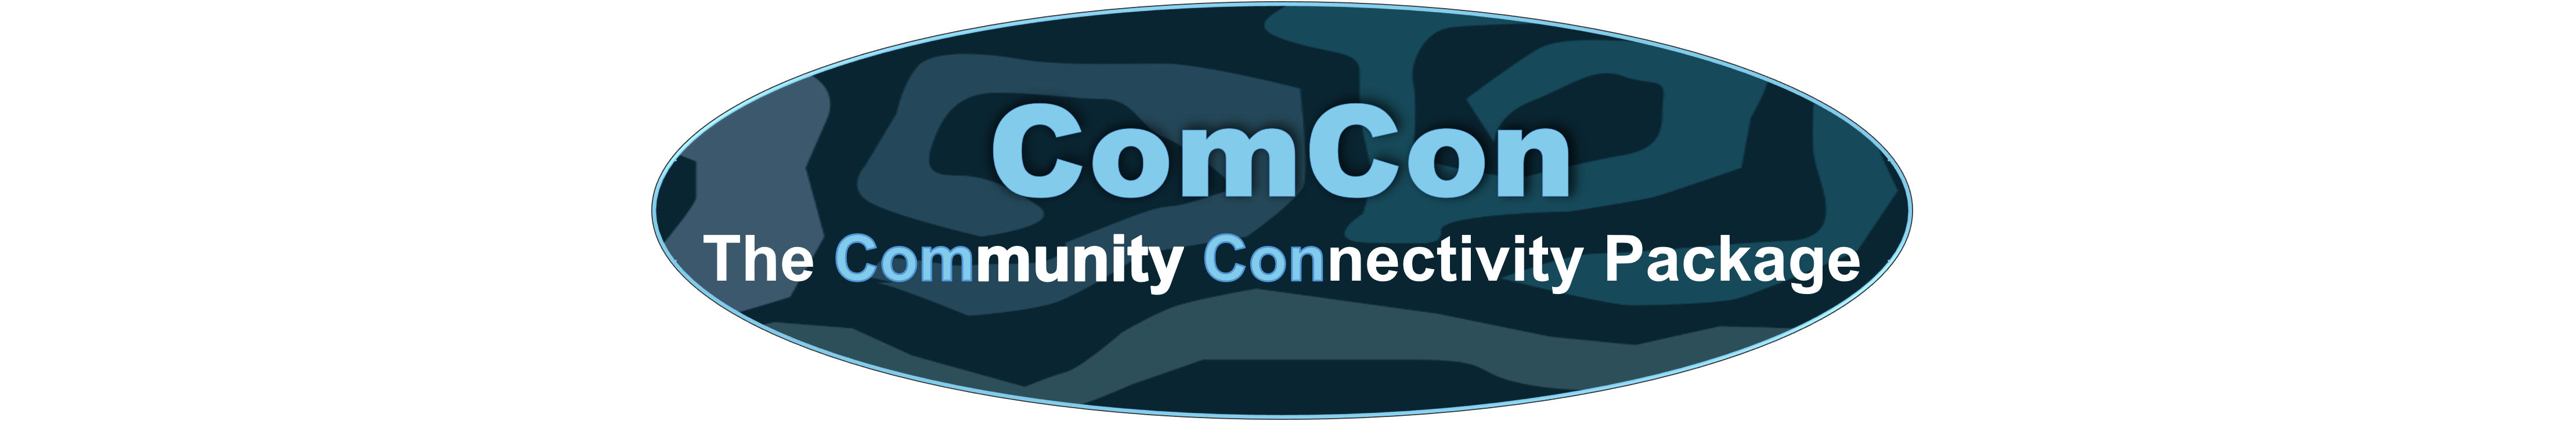


Welcome to ComCon!

This package facilitates multi-species dispersal modeling using Lagrangian particle tracking with Ocean Parcels and NEMO hydrodynamic data.

You can use the package in three modes:
  1. Interactive Mode: Step-by-step guided workflow
  2. Automatic Mode: Run entire workflow with preset parameters
  3. Manual Mode: Access individual functions for custom workflows



Please select a mode below:


Dropdown(description='Mode:', options=(('Interactive Mode', 'interactive'), ('Automatic Mode', 'automatic'), (…

Button(button_style='success', description='Start', icon='check', style=ButtonStyle())

Output(layout=Layout(height='0px', overflow='hidden'))

In [1]:
import comcon

It will tell you to run the following command to begin:

    from comcon.interactive import *
    workflow_step(1)

For now copy and paste this into the next cell and run it:

In [2]:
from comcon.interactive import *

---

## Step 1: Hydrodynamic and Trait Data

This is the first official step of the interactive workflow. This step sets up the two foundations of any connectivity analysis: the ocean current data that will drive particle transport and the species trait data that will determine how we filter the results.

### What parameters to set:

ComCon will walk you through selecting your hydrodynamic and trait data in the next step. Here is what to input for this example:

**Loading hydrodynamic data**
- Select Option 1: Download from Copernicus Marine Service

**Copernicus credentials:**
- Input the username and password for your Copernicus Marine Service account

**Dataset selection:**
- Use dataset ID: `cmems_mod_nws_phy-cur_anfc_1.5km-2D_PT1H-i`

For this example we will assess the connectivity of *P. vulgata* across its distribution in the south-west of the English Channel (Devon and Cornwall). Therefore we are using the **Atlantic - European North West Shelf - Ocean Physics Analysis and Forecast** hydrodyanmic model. This model has a spatial resolution of ~1.5km, uses surface (2D) data only and has an hourly temporal resolution. 

**Hydrodynamic Extent:**
- Longitude range: -7 to 2 
- Latitude range: 48 to 52 

Remember that the spatial extent of your hydrodynamic data needs to be much larger than your actual study area for which you are assessing connectivity of a given species. The hydrodynamic extent is the entire area in which your propagules can disperse not just settle within. Therefore, choosing an area on the generously bigger side is a safer bet in case some of your propagules travel very large distances. 

**Species traits:**
- When asked for a trait source, choose **Built-in database**
- Select *Patella vulgata* from the database
- The trait values (spawning Oct–Jan, PLD 2–10 days) will be loaded automatically

**Temporal buffer:**
- If asked about temporal buffers, you can enter 0 for both. Buffers are needed for trait sensitivity analysis (Vignette 3) but not for a basic analysis

**Simulation Year:**
- Choose 2024 as the start year of this simulation

ComCon will calculate that the simulation needs to run from 1 October 2024 to approximately 10 February 2025 (spawning end + maximum PLD). It will then download the hydrodynamic data from Copernicus. This may take several minutes depending on your internet connection.


---

Now run the next cell to start the workflow:

In [3]:
workflow_step(1)

Data Source



  This package uses hydrodynamic data from the Copernicus Marine Service.
  
  Use the link below to set up a free account to browse and select your hydrodynamic data.
  
  After finding and clicking on the data you want to use, click on 'Data access' and copy the dataset ID.
  
  For example: cmems_mod_ibi_phy_anfc_0.027deg-2D_PT1H-m
  
  To access the data, you will need:
    - A stable internet connection
    - Username and password
    - Dataset ID number (e.g. cmems_mod_ibi_phy_anfc_0.027deg-2D_PT1H-m)
    - Longitude and latitude ranges of your study area



Species Trait Data



  This package requires species trait data with information on:
    - Planktonic larval duration (PLD)
    - Timing of spawning for each species
  
  This data will be used to run the species-specific connectivity analyses, as well as select the time range of the hydrodynamic data and the simulation runtime.
  
  You can upload this data via this workflow or select species and their traits directly from an integrated dataset of common species found in intertidal rocky shore habitats of the temperate Atlantic. This dataset is based on a literature review of peer-reviewed data.
  
  For more information, see 'Part 3: Step 1' and 'Part 5: Species Traits CSV Format' in the User Guide.



Project Setup



  ComCon organises all outputs into a project folder.
  Each project gets its own directory with subfolders for configuration, data, figures, simulation output and results.
  
  This keeps your work organised and prevents files being overwritten between different analyses.



... (16 outputs left out)

  ✓ Step 1 completed.



  To continue, run: workflow_step(2)


Outputs: Species traits, hydrodynamic parameters, dispersal period



Save session checkpoint? (yes/no) [default: yes]:  no



To continue, run in the next cell:
workflow_step(2)



---

## Step 2: Species Occurrence Data

ComCon needs to know where your species is found so it can set up appropriate release and settlement locations. This step loads occurrence records (here from GBIF) and cleans the data based on our habitat filtering selection and also allows you to select your study area (the area in which you are interested in assessing connectivity). 

### What parameters to set:

**Study area polygon:**
- Draw a polygon covering the southern English coast, similar to the one drawn below in the example

This polygon defines where you want to focus your connectivity analysis. Alternatively, you can load an existing GeoJSON file, if you have one.

**Data source:**
- Choose GBIF

ComCon will search GBIF for *Patella vulgata* records within your study area.

**Habitat filtering:**
- Choose Coastal

This is appropriate for intertidal species like limpets. ComCon will create land and coastal masks from the hydrodynamic data and filter out any occurrence records that fall on land or in the open ocean.

You will see a summary showing how many records were downloaded and how many remain after data cleaning. A visualisation will display the filtered occurrence points on a map.

> **Tip:** If you have your own species distribution data (e.g., from field surveys), you can upload it as a CSV file instead of using GBIF. See the User Guide, Part 5 for the required CSV format.

---

<img src="study_area.jpg" alt="Study area selection of the South-West of England" style="max-width: 600px; width: 100%;">

*Photo: Study area selection of the South-West of England.*

Once Step 1 has finished running, run the code for Step 2:


This package has the option to use species-specific occurrence data to determine appropriate release and settlement areas for each species.

In this step, you will select your study area and choose your data source.

In step 3, you then have the option to:
  - Release particles from all locations in your study area or known occurrences
  - Settle particles from all locations in your study area or known occurrences





Data source options



  Option 1: Download occurrence data from GBIF (Global Biodiversity Information Facility)
    - Automatically determines suitable sites based on species distributions
    - Uses the species identifiers (AphiaID or scientific name) from your trait dataset
    - Same data will be used for both release and settlement
    - Requires a stable internet connection
  
  Option 2: Provide your own species occurrence data
    - This can be species occurrence data or habitat suitability data
    - Must be in CSV format with columns: species, latitude, longitude
    - Species names must match those in your trait dataset
    - You can provide different datasets for release and settlement in step 3
    - See 'Part 5: Occurrence Data CSV Format' in the User Guide for format details



Note: If you plan to release and settle everywhere in your study area, you still need to complete this step to set up the simulation.




GBIF Website


https://www.gbif.org/

For more information, see 'Part 3: Step 2 (Species Occurrence Data)' in the User Guide.





... (10 outputs left out)


Using data source: gbif

You have two options for downloading GBIF species occurrence data:

1. Download occurrences for specific species from your trait database
  - Recommended for connectivity analysis

2. Download all species in your study area
  - For exploratory analysis only as trait data will be missing



Choose mode (1 or 2) [default: 1]:  1




  [1/2] patella vulgata...
  [2/2] sabellaria alveolata...

Downloaded 3153 occurrence records




Visualising the Hydrodynamic Data


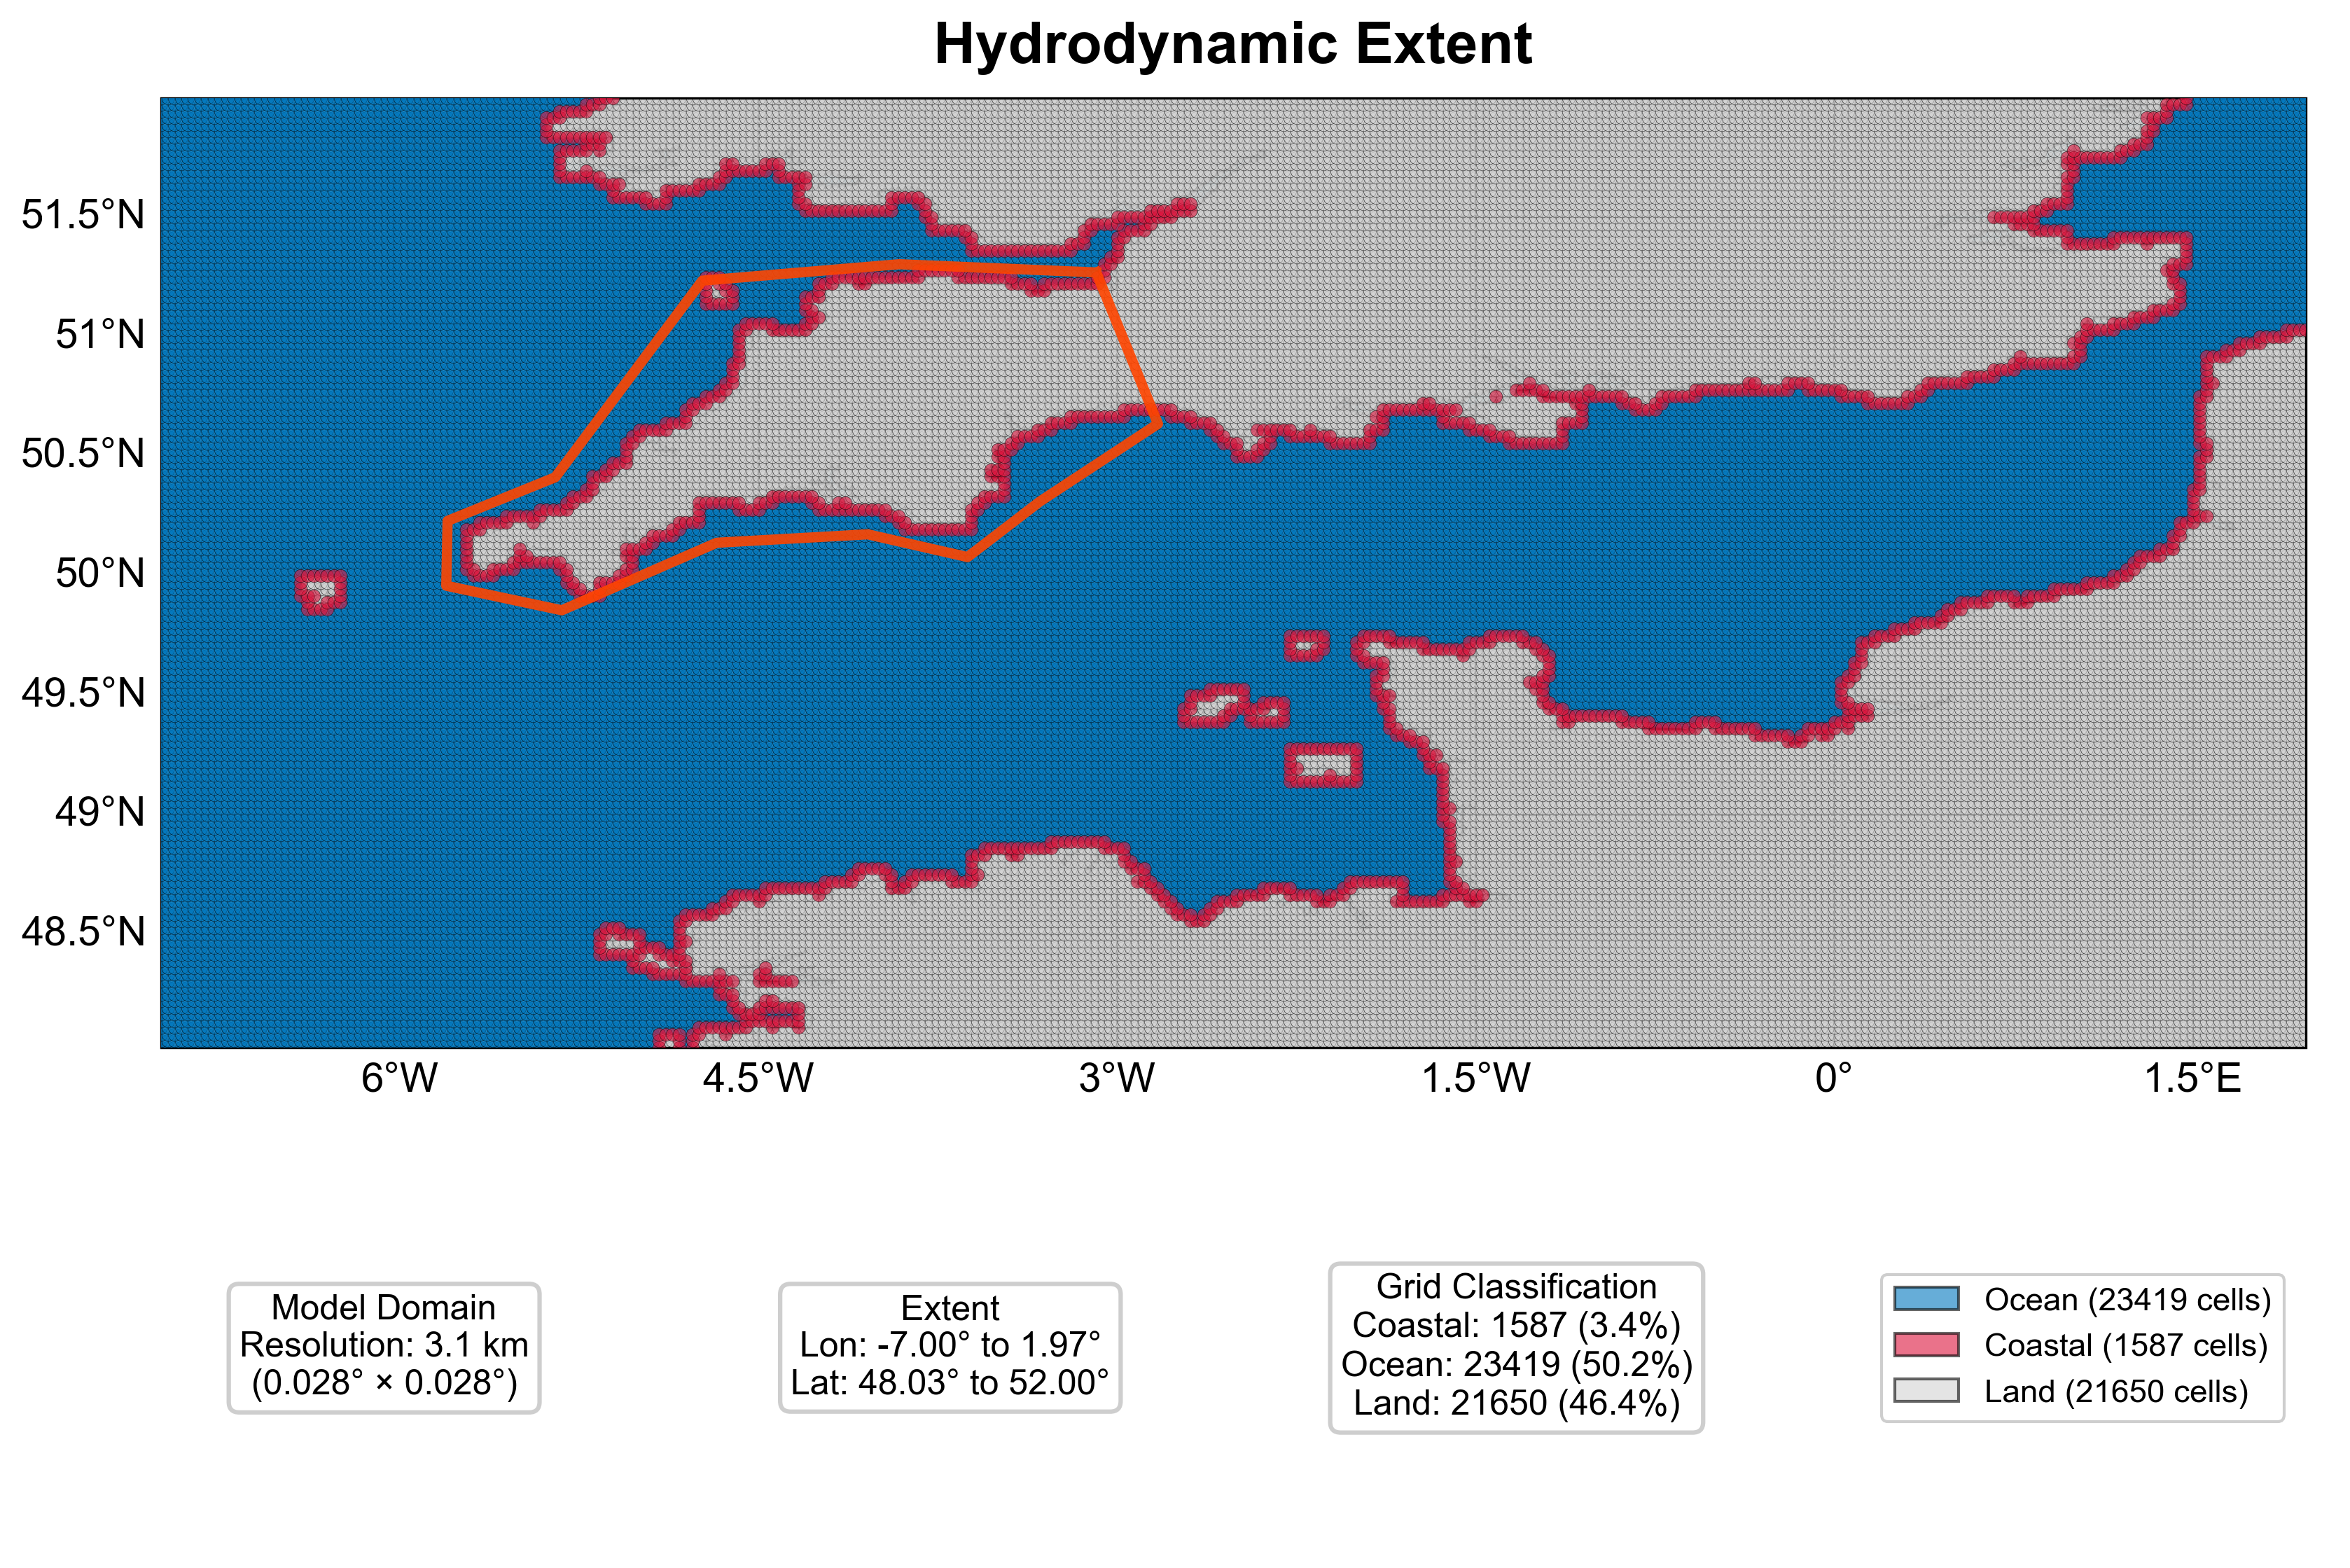


Save domain map? (yes/no):  no



Using saved habitat filtering preference: coastal




Coastal Filtering



  Model resolution: 3.1 km
  Coastal zone: ~9.3 km total. Applies a 1 cell buffer landward and seaward for intertidal zone.
  Keeps species within ~3× grid spacing.




- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Filtering Results
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    Original occurrences: 3153
    After filtering: 2707
    Removed: 446 (14.1%)
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 




Species Occurrence Data: Sample Size Validation


patella vulgata: 1892 records
sabellaria alveolata: 815 records

- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Summary
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    Adequate sample size: 2/2 (100.0%)
    Low sample size: 0
    No records found: 0
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 

Validation Passed
2 species have adequate sample sizes for analysis



Save filtered species data to CSV? (yes/no):  no


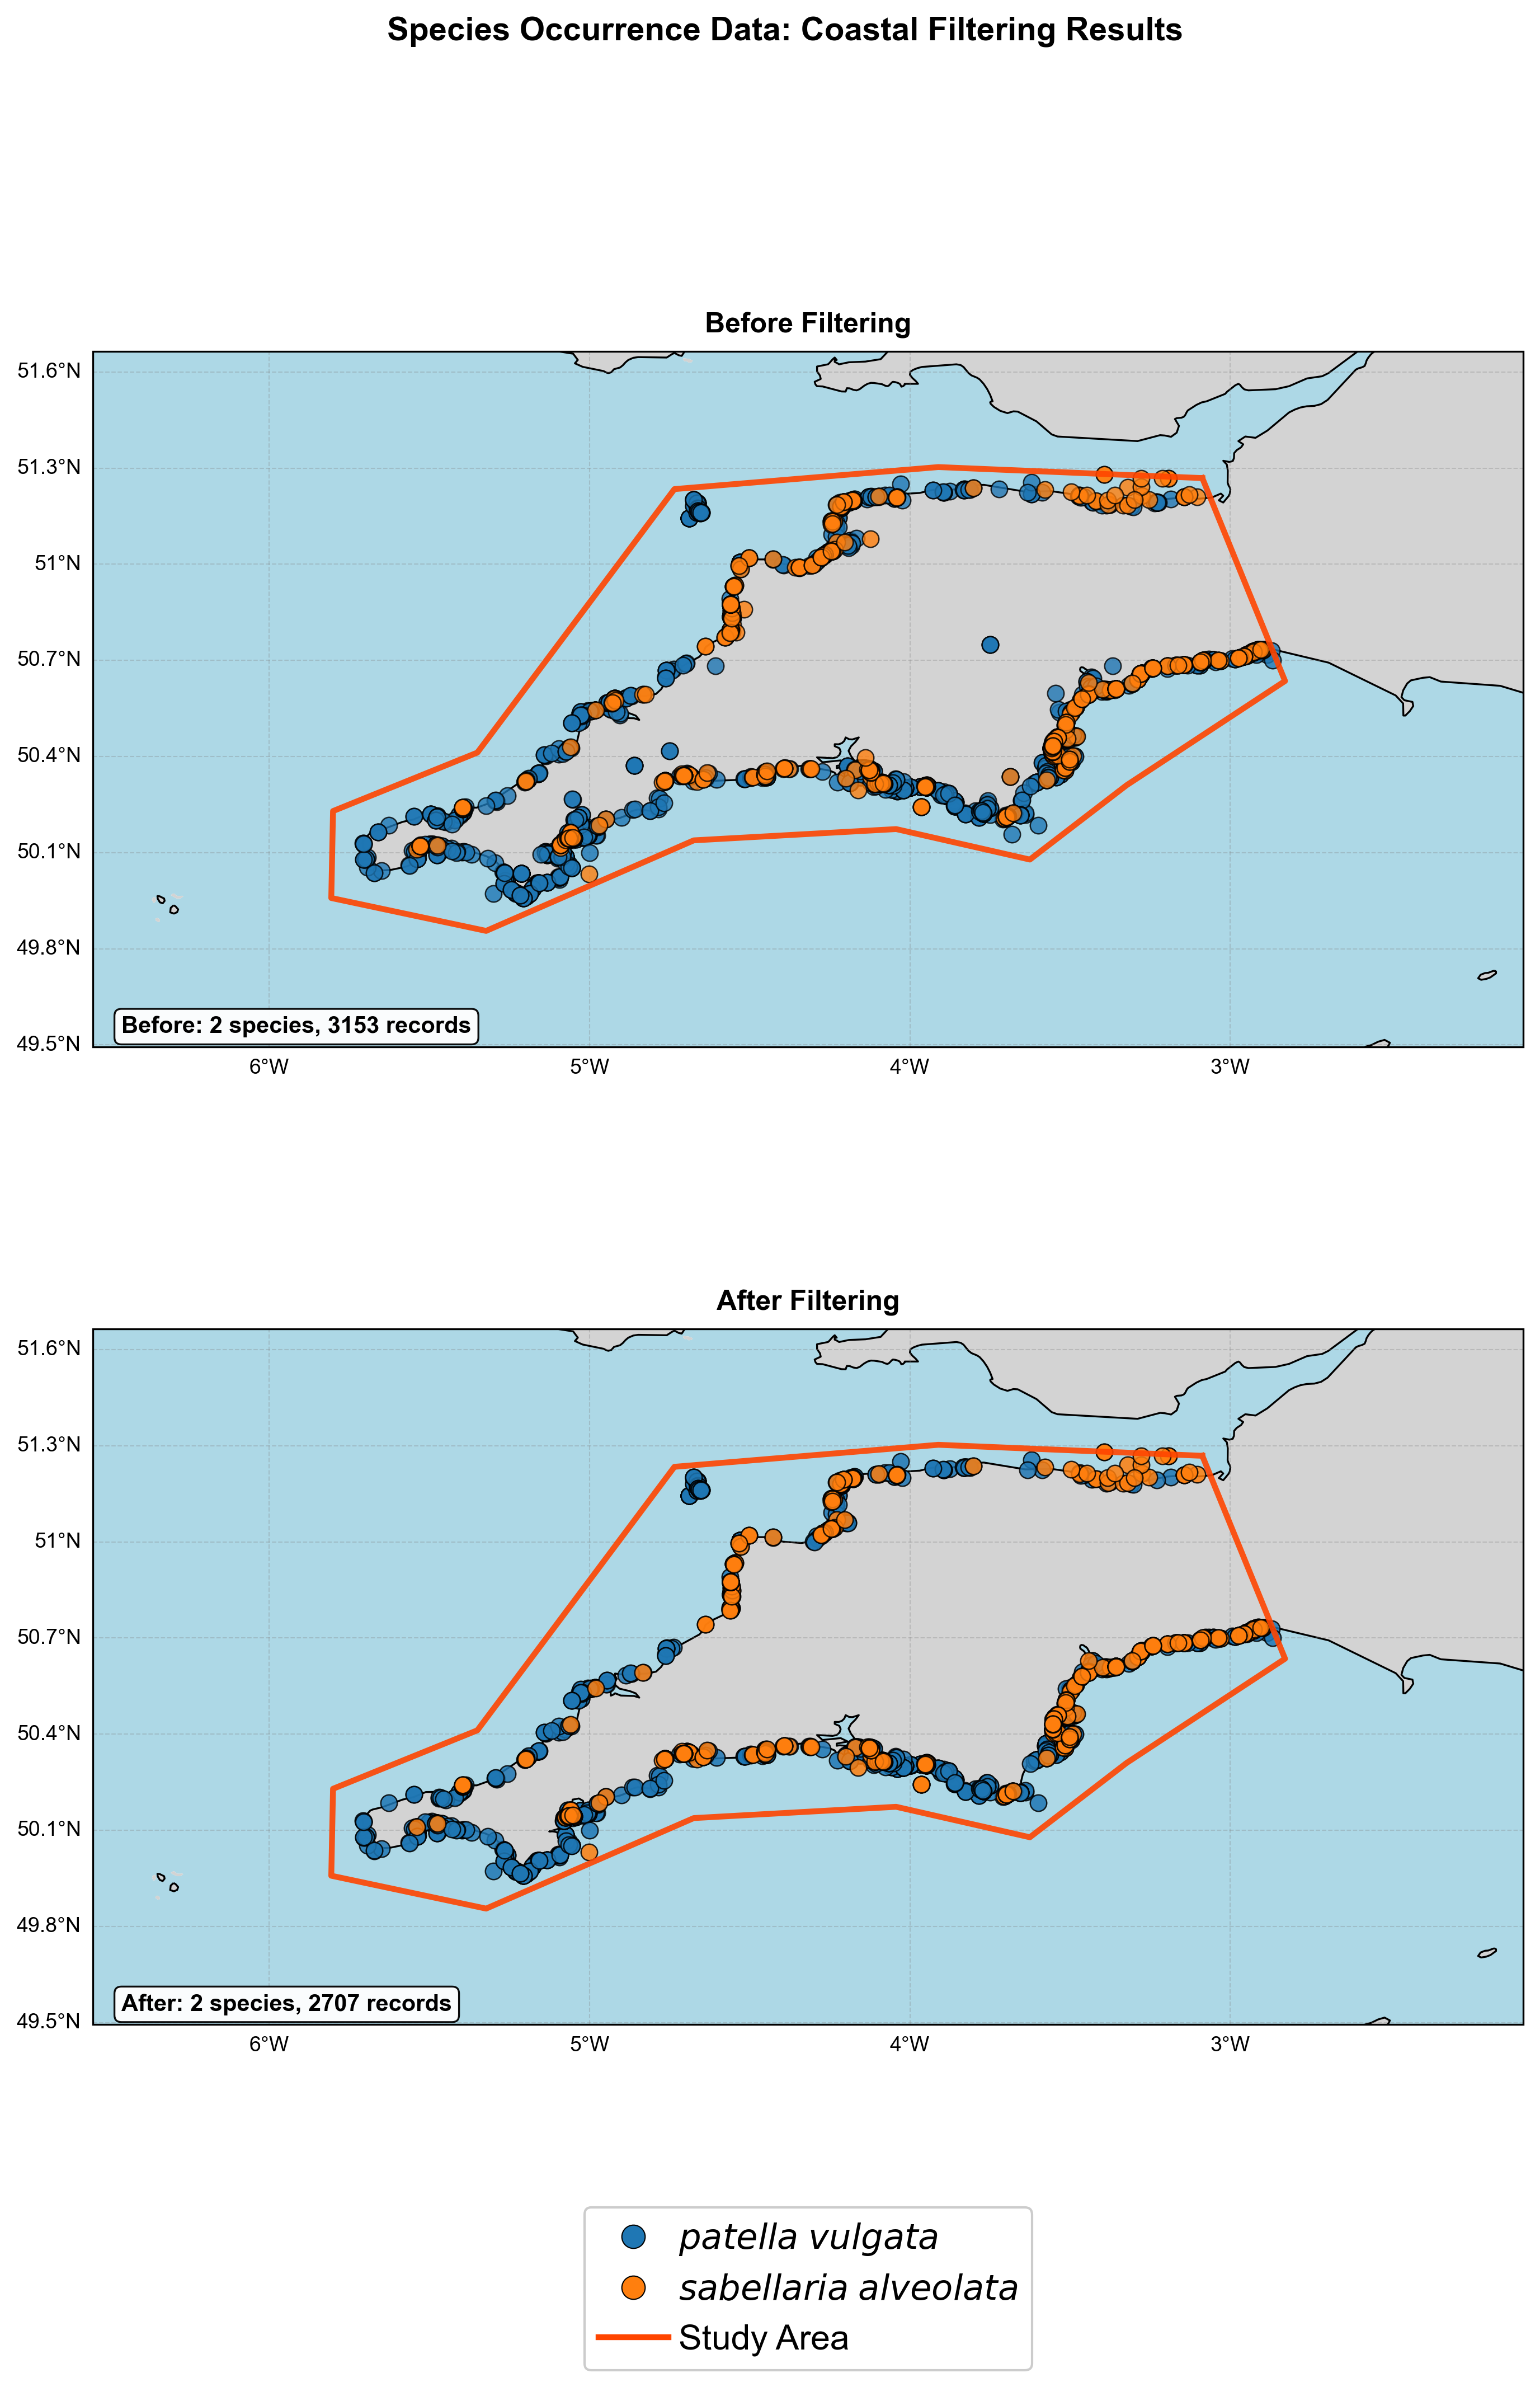


Save species map? (yes/no):  no


  ✓ Step 2 completed.



  To continue, run: workflow_step(3)


Outputs: Cleaned species occurrences, land/coastal masks, study area polygon



Save session checkpoint? (yes/no) [default: yes]:  no



To continue, run in the next cell:
workflow_step(3)



In [4]:
workflow_step(2)

---

## Step 3: Release and Settlement Setup

This step maps the species occurrence data onto the hydrodynamic model grid to create release sites (where particles will be released from) and settlement sites (where particles can settle to). It also creates the OceanParcels fieldset that will drive the particle simulation.


### What parameters to set:

#### Release and Settlement Strategy
- For release sites choose Option 2: Species-specific habitat (based on GBIF data)
- For settlement sites choose Option 2: Species-specific habitat (same as release data)

In this example, we will release and settle particles only where the species is currently recorded.


#### Release interval
- Choose weekly

Weekly releases capture temporal variation in ocean current conditions throughout the spawning season, ensuring that larvae experience a representative range of hydrodynamic conditions whilst still keeping the total particle count manageable.

#### Number of Particles
- Go with the default of 100

In a realistic simulation you will want to set the particle number much higher, e.g. 1000–10000. This does not represent the actual number of larvae being released but rather the resolution at which you are sampling possible dispersal pathways. Think of it like sample size. By increasing the number of particles, you increase the likelihood of capturing rare but important long-distance connections and produce more stable, reproducible connectivity estimates. For this example, 100 is sufficient to demonstrate the workflow and see general patterns.


#### Horizontal Diffusivity
- Go with the default of 1 m²/s

This is representative of standard small-scale random motion caused by turbulence in marine systems

ComCon will display a summary showing how many release and settlement sites were created. It will also create the OceanParcels fieldset (the velocity field used to advect particles) and set up reflective boundaries to prevent particles from getting stuck on land.


---

Once workflow step 2 has finished running, run the below:

In [5]:
workflow_step(3)

Release and Settlement Strategy


This package has several options for releasing and settling propagules.

You have the option to release propagules from all sites in your study area or from known species-specific distributions.

For more information, see Section X in the User Manual.





Propagule Release Strategy



  Choose where particles should be released from.
  
  You can use the occurrence data from step 2, upload a different dataset or release from everywhere in your study area.
  
  Option 1: All sites in the study area
    - Release particles from all coastal sites in your study area
    - Does not use species occurrence data
    - This is suitable for assessing maximum dispersal scenarios or for data-poor scenarios
    - Total release sites: 423
  
  Option 2: Species-specific habitat (based on GBIF data)
    - Release particles only from species-specific suitable habitat
    - This is suitable for trait-based analysis
    - Uses: Species distributions from GBIF data
    - Total unique release sites: 221
    - Sum across 1 species: 221 (includes shared sites)
  
  Option 3: Custom species occurrence data
    - Upload your own species occurrence or habitat suitability data (CSV format)
    - This can be a different CSV file from the data loaded in step 2
    - Required columns: species,


Choose release strategy (1/2/3):  2


Created release grids for 1 species
Total unique release sites: 221




... (17 outputs left out)


This package allows you to add a horizontal diffusivity value.

Horizontal diffusivity represents small-scale random motion caused by turbulence and applies evenly to all 
particles in the simulation.



Enter horizontal diffusivity (kh) in m²/s [default: 1]:  1


  ✓ Step 3 completed.



  To continue, run: workflow_step(4)


To continue, run in the next cell:
workflow_step(4)



---

## Step 4: Running the Simulation

This is the computationally intensive step. ComCon creates particles at each release site and tracks them through the ocean current field using OceanParcels.

### What parameters to set:

#### Output path:
- Provide a file path and name for the simulation output

The raw simulation output will be saved as a .zarr file (a format for storing large array data efficiently).

#### Output frequency:
- Choose 24 hours
  
Output frequency controls how often particle positions are recorded during the simulation. The default of 24 hours is fine for most analyses. It keeps file sizes manageable while providing daily position data. Higher frequency (e.g., 6 hours) gives more temporal detail but produces larger files.

#### Time step:
- Choose the default of 60 minutes
  
This is the interval at which particle positions are calculated during the simulation. The default of 60 minutes provides a good balance between accuracy and speed. Smaller timesteps are more accurate but slower.

#### Memory check:
ComCon will automatically check your system's available RAM and adjust processing chunk sizes accordingly. You do not need to do anything here. This is just informational. 

ComCon will then display a summary of simulation settings (runtime, output frequency, time step) and begin running the OceanParcels simulation with a progress bar. 

> **Tip:** If the simulation runs slowly or you experience memory issues, try reducing the number of particles or the study area extent. See the Troubleshooting section in the User Guide.

---

Once workflow step 3 has finished running, run the below:

In [6]:
workflow_step(4)

Running the Particle Simulation


The simulation will now run using the parameters you have configured.

For more information, see Section X in the User Manual.





Setting up the Simulation



Enter the output path and file name to save the simulation output:  D:\Python_Code\comcon_distribution\docs\vignettes\outputs\single_species


Output Frequency



  In a particle simulation, particles are advected at regular timesteps (e.g. every hour).
  You can save output less frequently than the simulation timestep to reduce file size.
  
  For example: Timestep = 1 hour, Output frequency = 6 hours.
    - Higher frequency = more temporal detail but larger files
    - Lower frequency = less detail but smaller files
    - Higher timestep = more detail but slower simulation runtime
    - Lower timestep = less detail but faster simulation runtime



... (4 outputs left out)

INFO:Output files are stored in D:\Python_Code\comcon_distribution\docs\vignettes\outputs\single_species.zarr.


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11491200.0/11491200.0 [32:15<00:00, 5935.67it/s]

Processing simulation results...

Output file size: 0.31 GB
Using memory-safe chunked loading (10000 trajectories per chunk)
Loading simulation results...
Opening zarr dataset...

- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Dataset properties
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    Trajectories: 419900
    Time steps: 134
    The dataset will be imported in chunks of 10000 trajectories
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
Importing chunk 1/42 (10000 trajectories)...
Chunk 1...
Importing chunk 2/42 (10000 trajectories)...
Chunk 2...
Importing chunk 3/42 (10000 trajectories)...
Chunk 3...
Importing chu

  ✓ Step 4 completed.



  To continue, run: workflow_step(5)


To continue, run in the next cell:
workflow_step(5)



---

## Step 5: Post-Processing

The raw simulation output contains all particle trajectories regardless of biological constraints. Post-processing, our other most time-intensive step of this workflow, applies three sequential filters to extract only the trajectories that are biologically relevant for *P. vulgata*:

1. **Spawning filter:** Retains only particles released during the spawning window (Oct–Jan).
2. **PLD filter:** Crops each trajectory to the species' pelagic larval duration (2–10 days) and checks whether the particle reached suitable settlement habitat within that time
3. **Habitat filter:** Confirms particles were released from suitable habitat for the species

### What parameters to set:

**Settlement buffer:**
- Choose a buffer of 1 cell

ComCon will ask for a buffer size (in grid cells) around settlement sites.  A buffer of 1 allows particles to settle if they are within one grid cell of a known settlement location, accounting for the fact that grid cells may not perfectly align with actual habitat.

After filtering, ComCon will display a summary showing how many trajectories passed each filter. You will typically see a large reduction. This is expected. Many particles will be released outside the spawning window (removed by filter 1), or will not reach settlement habitat within the PLD (removed by filter 2).

---

Once step 4 has finished running, run the below cell to start post-processing.

In [7]:
workflow_step(5)

Species-Specific Filtering


The simulation output will now be filtered using species-specific traits.

This includes:
  - Spawning window filtering
  - Planktonic larval duration (PLD) filtering
  - Release and settlement habitat suitability filtering

For more information, see Section X in the User Manual.





Starting Post-processing



2. Applying spawning seasonality filter...
Species assignment...

Assigning species to trajectories...

Creating unique trajectory IDs for 1 species...
Species assignment...
   patella_vulgata: 397800 trajectories
Species assignment complete: 1 species with trajectories.

3. Applying day-wise PLD filter...


Enter buffer size around settlement sites [default: 1 adjacent grid cell]:  [default: 1]:  1



Processing PLD filter for patella vulgata...
  PLD window: 2 - 10 days
  Settlement sites: 221 (with buffer: 1063)
  174291 successful trajectories
  Successful trajectories per day: day 2: 127742, day 3: 16080, day 4: 7889, day 5: 5569, day 6: 5551, day 7: 4073, day 8: 2465, day 9: 2897, day 10: 2025

4. Applying release location filter...
  patella_vulgata: 174291 trajectories from release sites

- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  Post-processing Summary
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
    patella_vulgata: 174291 successful trajectories from 18 release cohorts
    
    Total successful trajectories: 174291
- - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 




  ✓ Step 5 completed.



  To continue, run: workflow_step(6)


To continue, run in the next cell:
workflow_step(6)



---

## Step 6: Connectivity Analysis using Type 1: Connectivity Metrics

This is where we address our research question: What are the dispersal characteristics of *P. vulgata* along the southern English coast? 

Type 1 analysis provides the fundamental descriptive metrics of larval dispersal: How many larvae settle, how far they travel, and how much local recruitment occurs. These metrics form the baseline for understanding any species' connectivity before moving on to more complex network or sensitivity analyses.

### What parameters to set:

**Analysis scope:**
- Choose Option 2: Per-species only

Since we only have one species, the community level and per-species analyses are identical.

**Which analyses to run:**
- Select **Yes** for Type 1 (Connectivity Metrics)
- Select **No** for Type 2 and Type 3 for now.

We will cover these in Vignettes 2 and 3

### Understanding the Type 1 Output

ComCon will display a table of connectivity metrics. Here is what each metric tells you:

|Metric   | What It Means |
|:---------|:---------------|
| **Released** | The total number of particles released during the species' spawning window across all release sites and cohorts. |
| **Settled** | The number of released particles that successfully reached suitable habitat within their PLD window. |
| **Settlement rate** | The proportion of released particles that successfully settle. Calculated as: settled ÷ released × 100. Rates vary widely between species and study areas depending on current patterns, habitat availability and PLD. |
| **Mortality rate** | The proportion of released particles that fail to settle. Calculated as: 100 − settlement rate. Note that this represents computational mortality (particles that did not encounter suitable habitat within their PLD window), not realised mortality which is dependent on a range of additional biological factors not accounted for in the model such as competition for resources, predation and environmental stochasticity. |
| **Local recruitment rate** | The proportion of settled particles that return to within the settlement buffer of their own release site. High values indicate populations that may be more self-sustaining; low values suggest greater dependence on larval supply from other sites. |
| **Min/Mean/Max net displacement** | The straight-line (Haversine) distance from each particle's release point to its settlement point. This measures where larvae end up relative to where they started, not the total path they travelled. A value of 0.0 km means the particle settled at or very near its release site. |
| **Min/Mean/Max PLD** | The realised time each particle spent in the water column before settling. This may be shorter than the species' maximum PLD if suitable habitat is encountered quickly. |

---

Once workflow step 5 has finished running, run the below:

In [6]:
workflow_step(6)


This package includes three types of connectivity analyses:





Type 1: Connectivity Metrics


  - Settlement & mortality rates
  - Local recruitment
  - Dispersal distance
  - Realized PLD




Type 2: Network Analysis


  - Functional roles (source, sink, local recruitment)
  - Centrality measures (betweenness, closeness, degree
  - Composite hotspot rankings, network maps and connectivity matrices




Type 3: Trait Sensitivity Analysis


... (6 outputs left out)

Released: 397800 trajectories
Settled: 174291 trajectories
Settlement rate: 43.8%
Mortality rate: 56.2%
Local recruitment rate: 19.1%, within 1-cell buffer of release site (33223 trajectories)
Min net displacement: 0.0 km
Mean net displacement: 9.6 km
Max net displacement: 88.2 km
Min PLD: 2.0 days
Mean PLD: 2.8 days
Max PLD: 10.0 days



Save Type 1 results to CSV? [default: no]:  no



 Type 1 analysis complete






Completed analyses:
  Type 1: Connectivity Metrics




### Interpreting the Results for *P. vulgata*

> Note: The results shown in this vignette will not match your results exactly because the model includes stochastic particle movement to represent small-scale turbulence and natural variability in larval transport. As a result, trajectories differ slightly between simulation runs, even under identical settings.

**Settlement rate:** Settlement rates vary widely depending on a range of biophysical factors including the density of suitable habitat in your study area, local current patterns and coastline geometry. There is no simple relationship between PLD length and settlement success. Your results reflect the specific combination of oceanography and habitat distribution in your study domain. 

**Local recruitment:** For a short PLD species, we might expect a relatively high proportion of settled particles to have returned to or near their release site compared to species with longer PLDs. However, this also greatly depends on local current patterns and cannot be generalised across species and areas.

**Net displacement:** Short PLDs generally limit both the maximum and mean distance larvae travel, relative to  species with longer PLDs. 

**PLD:** The PLD values reported in the output table are the actual time each settled particle spent in the water column (realised PLD), not the species' literature value. If suitable habitat is encountered before the end of the PLD window, particles settle earlier. In habitat-rich areas, mean realised PLDs may be considerably shorter than the maximum.

What do your results show? Do they match general predictions or are there surprises? 

> Note: These results are based on a low-resolution example (100 particles per site per release event). For robust scientific conclusions, you would want to increase particle numbers and validate against field observations. Type 1 metrics estimate potential connectivity based on physical transport. They do not account for post-settlement survival or other biological processes.

---

## Summary

You have now completed a full single-species connectivity analysis using ComCon by:

1. **Setting up** the ocean current data and species traits
2. **Downloading** species occurrence data and mapping it to the model grid
3. **Setting up** the simulation
4. **Simulating** larval dispersal using Lagrangian particle tracking
5. **Filtering** the results using species-specific biological traits
6. **Calculating** connectivity metrics to quantify dispersal patterns

The Type 1 connectivity metrics gave us an overview of dispersal outcomes. How many larvae settled, how far they travelled and how much local recruitment occured.

### What Next?

- **Vignette 2** extends this to a multi-species analysis and introduces **Type 2: Network Analysis**. This examines the overall structure of connectivity between sites to identify which locations are most important for maintaining larval exchange across the system. Rather than focusing on individual dispersal events, it evaluates how the full network functions and identifies key connectivity hotspots. 
- **Vignette 3** demonstrates **Type 3: Trait Sensitivity Analysis**, testing how robust your results are to uncertainty in species trait data.

Vignettes 2 and 3 use **Manual Mode** rather than **Interactive Mode**. Vignette 1 is also available in **Manual** and **Automatic Mode**. **Manual Mode** gives you direct access to individual ComCon functions, which is useful for creating reproducible analyses and testing different scenarios without re-running the full workflow each time.

---